# **Proyecto: Simulación de proceso de guerrillas utilizando el modelo de coalescencia - fragmentación de grupos guerrilleros - VERSION C++**

Presentado por:

* Juan Esteban Gómez Gómez
* Jose Luis Martinez Diaz
* William David Rincón Verano
* Serena Triviño Sáenz


## Objetivo

Se busca realizar la simulación del algoritmo que relaciona la coalescencia (unión) - fragentación de unidades de ataque, se quiere obtener la distribución en el estado estacionario para el número de unidades $n_s$ con una fuerza de ataque $s$ y observar como es la dependencia de $\alpha$ de la ley de potencias ($n_s \sim s^{-\alpha}$) en función del parámetro $\nu$.

**Algoritmo:** El sistema tiene una fuerza total $\sum_i s_i = N$. Luego, en cada paso se tiene:

1. Se elige una unidad $i$ con probabilidad proporcional a $s_i$
2. Con una probabilidad de $\nu$, la unidad $i$ se fragmenta en $s_i$ unidades de fuerza 1
3. Con probabilidad $1 - \nu$, la unidad $i$ se fusiona con otra unidad $j$ también con probabilidad $s_j$. Luego forman una unidad de fuerza $s_i + s_j$

Adicionalmente, nuestra condición inicial es $N$ unidades de fuerza 1

Para la implementación del algoritmo en **C++** usamos `std::map<int,long long>` que lo que hace es asociar cada fuerza $s$ con el número de unidades $l_s$ que tienen dicha fuerza. Ya que las unidades con la isma fuerza se puede intercambiar, tenemos que la representación es exacta y no hay aproximación en este caso. Para poder asignar una probabilidad proporcional a $s$, tomamos un entero uniforme $r$ el cual está entre $[0, N)$.

## Código C++ y compilación

In [1]:
%%writefile guerrilla.cpp

#include <chrono>
#include <cstdio>
#include <cstdlib>
#include <map>
#include <random>
#include <string>

// total = suma de s * L[s] sobre el mapa actual y nos devuelve la fuerza s de la unidad elegida.
// nsteps es el número total de pasos del algoritmo.

using Partition = std::map<int, long long>;                                            // aquí fuerza s -> numero de unidades

static int pick_size_biased(const Partition& L, long long total, std::mt19937_64& rng){
    std::uniform_int_distribution<long long> U(0, total - 1);
    long long r = U(rng), cum = 0;                                                     // r que es un entero uniforme en [0,N)
    for (const auto& kv : L){                                                          // va recorriendo el mapa acumulando s * L[s]
        cum += static_cast<long long>(kv.first) * kv.second;
        if (r < cum) return kv.first;                                                  // en el caso de que r caiga en el tramo de la fuerza s
    }
    return L.rbegin()->first;                                                          // no deberia ocurrir (ojalá)
}


static void remove_one(Partition& L, int s){                                           // Aquí se quita una unidad de fuerza s del mapa (se borra la entrada si queda en 0).
    auto it = L.find(s);
    if (--(it->second) == 0) L.erase(it);
}


int main(int argc, char** argv){
    if (argc < 6){
        std::fprintf(stderr, "Uso: %s N nu nsteps seed out_prefix\n", argv[0]);
        return 1;
    }

    const long long N = std::atoll(argv[1]);                                       // Es la fuerza total (la conservada)
    const double nu = std::atof(argv[2]);                                          // Es la probabilidad de fragmentación
    const long long nsteps = std::atoll(argv[3]);                                  // Son los pasos totales
    const unsigned long long seed = std::strtoull(argv[4], nullptr, 10);
    const std::string prefix = argv[5];

    std::mt19937_64 rng(seed);                                                     // Para los números aleatorios
    std::uniform_real_distribution<double> U01(0.0, 1.0);

    Partition L;                                                                   // La condición inicial es N unidades de fuerza 1
    L[1] = N;

    Partition acc;                                                                 // Es el acumulador de L[s] sobre las muestras
    long long nsamples = 0;                                                        // Es el número de muestras acumuladas
    const long long sample_every = N / 4;                                          // Se muestrea 4 veces cada N pasos


    const auto t0 = std::chrono::steady_clock::now();                              // Aquí ya va el algoritmo y como queremos ver el tiempo, se contabiliza desde acá


    for (long long step = 0; step < nsteps; ++step){                               // Elegimos una unidad i proporcional a s_i y la sacamos del sistema
        int si = pick_size_biased(L, N, rng);
        remove_one(L, si);

        if (U01(rng) < nu){                                                        // Es la fragmentacion, i a s_i unidades de fuerza 1
            L[1] += si;
        }
        else{                                                                      // Coalescencia con otra unidad, j proporcional a s_j (j != i)
            long long rest = N - si;                                               // fuerza total sin contar a i
            if (rest == 0) {                                                       // i era la unica unidad y no hay con quien fusionarse
                L[si] += 1;
            }
            else{
                int sj = pick_size_biased(L, rest, rng);
                remove_one(L, sj);
                L[si + sj] += 1;                                                   // Es la nueva unidad de fuerza s_i + s_j
            }
        }

        if ((step % sample_every) == 0) {                                          // Se acumula el histograma L[s] para promediarlo después
            for (const auto& kv : L) acc[kv.first] += kv.second;
            ++nsamples;
        }
    }                                                                              // Hasta aquí llega el algoritmo


    const double dt = std::chrono::duration<double>(std::chrono::steady_clock::now() - t0).count();


    FILE* fh = std::fopen((prefix + "_hist.txt").c_str(), "w");                                       // Para guardar el histograma promediado <n_s>
    std::fprintf(fh, "# s  <n_s>   (N=%lld nu=%g muestras=%lld)\n", N, nu, nsamples);
    for (const auto& kv : acc)
        std::fprintf(fh, "%d %.8g\n", kv.first, static_cast<double>(kv.second) / nsamples);
    std::fclose(fh);

    std::printf("[C++] N=%lld nu=%g | %lld pasos | muestras=%lld | "
                "TIEMPO DE EJECUCION DEL ALGORITMO = %.3f s\n",
                N, nu, nsteps, nsamples, dt);
    return 0;
}

Writing guerrilla.cpp


- En la siguiente celda se compila el código de **C++**

In [2]:
import subprocess

comp = subprocess.run(["g++", "-O3", "-std=c++17", "-o", "guerrilla", "guerrilla.cpp"], capture_output = True, text = True) # Para no escribir en la terminal

### Función auxiliar de ejecución

Usamos `std::chrono` dentro de la parte en **C++** alrededor del bucle para ver el tiempo de ejecución del algoritmo.
El archivo que genera el programa se crea en la misma carpeta del notebook.

In [3]:
#Librerias
import numpy as np
import matplotlib.pyplot as plt

BIN = "./guerrilla"   # Ejecutable que está en la misma carpeta donde esté el notebook.

def run_sim(N, nu, steps, seed, tag, verbose = True):                                                                      # Aquí se ejecuta lo de C++ y obtenemos <n_s>
                                                                                                                           # Las columnas del archivo son s, <n_s>
    r = subprocess.run([BIN, str(N), str(nu), str(steps), str(seed), tag], capture_output=True, text=True, check=True)
    if verbose:
        print(r.stdout.strip())                                                                                            # incluye el tiempo del algoritmo (el que se midió en C++)
    hist = np.loadtxt(f"{tag}_hist.txt")
    return hist

## Simulación principal, con $\nu=0.01$

 $N=10.000$,
- Ya se simulan `STEPS` pasos del algoritmo desde la condición inicial de $N$ unidades de fuerza 1.
- Durante la simulación se tiene para que se acumule 4 veces cada $N$ pasos el número de unidades de cada fuerza, y luego se promedia: eso nos da $\langle n_s\rangle$ en el estado estacionario.

Nuestros parámetros son:

In [4]:
N     = 30000        # fuerza total del sistema (N > 10.000)
NU    = 0.01
STEPS = 900000000     # Los pasos totales del algoritmo
SEED  = 676767         # Semilla (Arbitraria)

Ejecución del Algoritmo:

In [5]:
hist = run_sim(N, NU, STEPS, SEED, "main")

[C++] N=30000 nu=0.01 | 900000000 pasos | muestras=120000 | TIEMPO DE EJECUCION DEL ALGORITMO = 188.419 s


### Figura de la Simulación

- Ahora, se grafica $\langle n_s\rangle/n_1$ en función de $s$  usando una escala (log-log).
- La recta de pendiente $-2.5$ es la guía del documento, anclada en $(1,1)$.

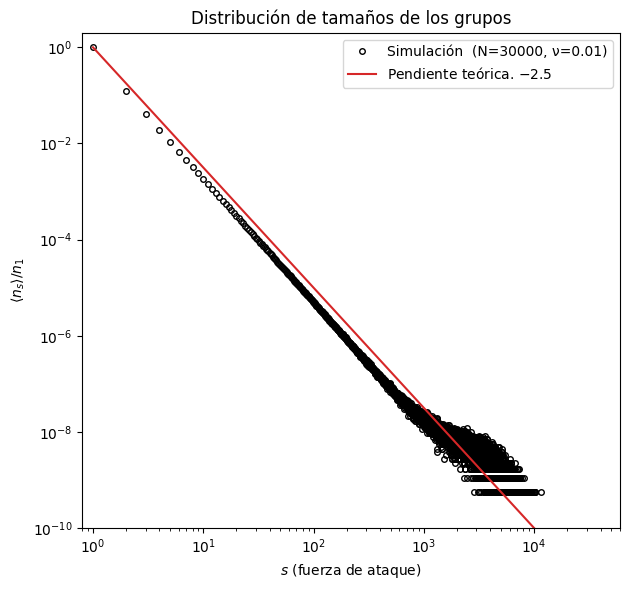

In [6]:
s = hist[:, 0]
ns = hist[:, 1]
n1 = ns[0]

#Graficación
fig, ax = plt.subplots(figsize = (6.4, 6))
ax.loglog(s, ns/n1, "o", mfc = "none", ms = 4, color = "k", label = f"Simulación  (N={N}, ν={NU})")
sg = np.logspace(0, np.log10(2*N), 100)

ax.loglog(sg, sg**-2.5, "-", color = "C3", lw = 1.5, label = r"Pendiente teórica. $-2.5$")
ax.set_xlabel(r"$s$ (fuerza de ataque)")
ax.set_ylabel(r"$\langle n_s\rangle / n_1$")
ax.set(xlim = (0.8, 2*N), ylim = (1e-10, 2), title = "Distribución de tamaños de los grupos")
ax.legend()
plt.tight_layout()
plt.show()

## Dependencia de $\alpha$ con $\nu$

- Ahora, se repite la simulación para varios valores de $\nu$ (todos con el mismo $N$). Para esto se usamos una semilla por valor y en cada una se estima $\alpha$ con un ajuste lineal de $\ln n_s$ frente a $\ln s$ en $2\le s\le100$ la tabla muestra el valor de $\alpha$ para cada $\nu$.

In [7]:
import pandas as pd

LISTA_NU = [0.005, 0.01, 0.05, 0.1]
STEPS = 50000000                                                                 # Pasos por simulación (con el mismo N de arriba)
NUEVA_SEED = 767676                                                              # Semilla nueva (Se puede poner el valor de la original si se quiere)

def fit_alpha(hist, smin=2, smax=30): # alpha es -m del ajuste lineal de ln(n_s) vs ln(s) en 2 <= s <= s_max
    s = hist[:, 0]
    n = hist[:, 1]
    m = (s >= smin) & (s <= smax) & (n > 0)                                     # Se descartan s=1 y los puntos con conteo cero.
    if m.sum() < 2:
        return np.nan
    return -np.polyfit(np.log(s[m]), np.log(n[m]), 1)[0]

alphas = [fit_alpha(run_sim(N, nu, STEPS, NUEVA_SEED, f"scan_nu{nu}", verbose = False)) for nu in LISTA_NU]
df = pd.DataFrame(dict(nu = LISTA_NU, alpha = alphas))
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
df

,nu,alpha
0,0.0050,2.5953
1,0.0100,2.5762
2,0.0500,2.5686
3,0.1000,2.5895


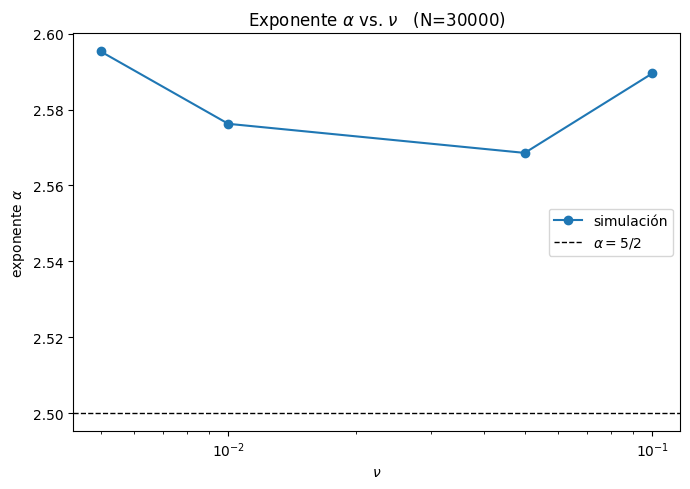

In [8]:
fig, ax = plt.subplots(figsize = (7, 5))
ax.plot(df.nu, df.alpha, "o-", label = "simulación")
ax.axhline(2.5, color = "k", ls = "--", lw = 1, label = r"$\alpha = 5/2$")
ax.set(xscale = "log", title = fr"Exponente $\alpha$ vs. $\nu$   (N={N})")
ax.set_xlabel(r"$\nu$")
ax.set_ylabel(r"exponente $\alpha$")
ax.legend()
plt.tight_layout()
plt.show()

### Distribuciones $\langle n_s\rangle/n_1$ para distintos $\nu$

- Aquí se muestra $\langle n_s\rangle/n_1$ en función de $s$ (log-log) para distintos valores de $\nu$.

In [9]:
import time

t0 = time.perf_counter()
resultados = list(map(lambda nu: run_sim(N, nu, STEPS, NUEVA_SEED, f"dist_nu{nu}", verbose = False), LISTA_NU))

print(f"{len(LISTA_NU)} simulaciones (N={N}) completadas en {time.perf_counter() - t0:.1f}")

hist_dist = dict(zip(LISTA_NU, resultados))                                     # nu -> histograma <n_s> (columnas: s, <n_s>)

4 simulaciones (N=30000) completadas en 38.9


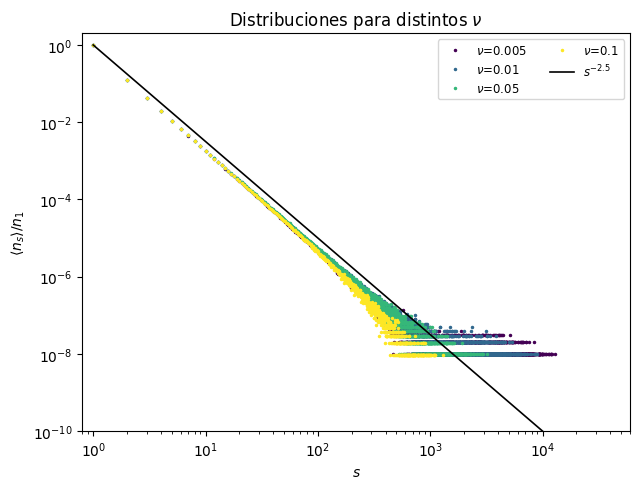

In [10]:
colores = plt.cm.viridis(np.linspace(0, 1, len(LISTA_NU)))
s_guia = np.logspace(0, np.log10(2*N), 100)

fig, ax = plt.subplots(figsize = (6.5, 5))
for c, nu in zip(colores, LISTA_NU):
    h = hist_dist[nu]
    mk = h[:, 1] > 0
    ax.loglog(h[mk, 0], h[mk, 1]/h[0, 1], ".", ms = 3, color = c, label = fr"$\nu$={nu}")

ax.loglog(s_guia, s_guia**-2.5, "k-", lw = 1.2, label = r"$s^{-2.5}$")

ax.set(xlim = (0.8, 2*N), ylim = (1e-10, 2), title = r"Distribuciones para distintos $\nu$")
ax.set_xlabel(r"$s$")
ax.set_ylabel(r"$\langle n_s\rangle/n_1$")
ax.legend(fontsize = 8.5, ncol = 2, loc = "upper right")
plt.tight_layout()
plt.show()